# Does Ramen's update point toward the true class? Cosine with the oracle cross-entropy gradient (DomainNet)

**Question.** Ramen adapts each test image with one SignSGD step along $\hat g_i$, a weighted average of *entropy*
gradients retrieved from its memory. Entropy minimisation sharpens whatever the model already predicts, right or
wrong. How close is $\hat g_i$ to the direction we would really want, the gradient of the **cross-entropy toward the
true label** $g^{CE}_i$? We measure the cosine similarity between the two for every test image.

**This is an oracle measurement, not a method.** $g^{CE}_i$ uses the ground-truth label, which a real test-time
method never has. The probe only *observes*: Ramen's predictions are unchanged (checked in section 3).

**Hypotheses (pre-registered in `ga_configs.py` before the full run).**
- **H1** Ramen's update carries image-specific information about the true class: median $\cos(\hat g_i, g^{CE}_i)$ is
  above the shuffled control $\cos(\hat g_i, g^{CE}_j)$, $j$ another image of the same batch.
- **H2** Memory helps where zero-shot is wrong: on zero-shot-wrong images, median $\cos(\hat g_i, g^{CE}_i)$ is above
  median $\cos(g_i, g^{CE}_i)$, with $g_i$ the image's own entropy gradient (pilot on 100 DomainNet images: mean
  $-0.31$ on the 38 wrong ones).
- **H3** Alignment explains outcomes: (a) among zero-shot-wrong images, the share Ramen fixes rises with
  $\cos(\operatorname{sign} \hat g_i, g^{CE}_i)$; (b) images Ramen breaks have a median
  $\cos(\operatorname{sign} \hat g_i, g^{CE}_i) < 0$.

**Why this test.** It asks directly whether Ramen's direction is "correct", using the cheapest possible oracle:
one extra backward pass per batch on a run that is otherwise Ramen itself.

**Runs.**

| Run | What it does | Uses true labels? |
|---|---|---|
| `NoAdapt` | zero-shot CLIP (cached) | no |
| `Ramen` | Ramen (cached) | no |
| `ga_probe` | Ramen + per-image gradient probe (`RamenGradientProbe`); predictions = Ramen's | **yes, only to measure** |

**Data.** DomainNet, 596,006 images, 6 domains (clipart, infograph, painting, quickdraw, real, sketch), 345 classes; CLIP ViT-B/32; `cfg/DomainNet/Ramen.yaml`: queue capacity $K = 300$, $k = 10$ neighbours per queue, $\beta = 5$, SignSGD $\eta = 0.01$. Mixed stream (all domains shuffled together), batch size 100.

**Seeds.** Seed 0 only (a seed sets the stream order). No accuracy changes here, so the noise floor does not apply;
all numbers are descriptive, from one stream.

**How the runs were produced.**
`CUDA_VISIBLE_DEVICES=0 python run_grad_alignment.py DomainNet 0` (after `--smoke smoke` on 200 images per domain, and
`check_gradients.py`). Results: `new_experiments/results/DomainNet_*_s0_ga_probe.pkl` and `_stats.pkl` (per-image probe
log).

**What counts as a result.** The four pre-registered tests (section 6), plus the descriptive figures.

**Sections.** 1 Setup · 2 Data · 3 Sanity and correctness · 4 Results · 5 Mechanism · 6 Hypotheses ·
7 Interpretation · 8 Glossary


## Method: what is measured

**Ramen (unchanged; notation shared by all Ramen notebooks).** Batch $x_1, \dots, x_B$ ($B = 100$); $\theta_0$ = the
affine weights and biases of every LayerNorm in the CLIP image encoder ($D = 39{,}936$ numbers), one copy per image.
$w_c$ = normalised text embedding of class $c$.
$$z_i = \frac{f_{\theta_0}(x_i)}{\lVert f_{\theta_0}(x_i) \rVert}, \quad
p_i = \operatorname{softmax}(100\, z_i^\top W), \quad \hat y_i = \arg\max_c p_{ic}, \quad
H_i = -\textstyle\sum_c p_{ic} \log p_{ic}, \quad g_i = \nabla_\theta H_i \big|_{\theta_0}$$
1. *Write* $(z_i, g_i, H_i)$ into queue $\mathcal M_{\hat y_i}$ (capacity $K$), **before** retrieval.
2. *Retrieve* from every non-empty queue $c \in C$ the $k$ entries nearest to $z_i$, $\mathcal N_k^c(z_i)$.
3. *Aggregate* $\displaystyle \hat g_i = \frac{1}{|C|} \sum_{c \in C} \sum_{j \in \mathcal N_k^c(z_i)}
   e^{-H_j} e^{-\beta d_{ij}}\, g_j$, with $d_{ij} = \lVert z_i - z_j \rVert$.
4. *Update* $\theta_i = \theta_0 - \eta\, \operatorname{sign}(\hat g_i)$, predict with $\theta_i$, reset to $\theta_0$.

**The oracle direction** (uses the true label $y_i$ — ground truth, available only in this experiment):
$$g^{CE}_i = \nabla_\theta \big[-\log p_{i y_i}\big]\Big|_{\theta_0}$$
the gradient of the cross-entropy toward the true class at the same unadapted parameters. Stepping along
$-g^{CE}_i$ raises $p_{i y_i}$ fastest.

**Measured per image.**
- $\cos(\hat g_i, g^{CE}_i)$: alignment of Ramen's update. **Positive = moving against $\hat g_i$ also lowers the
  true-label loss** (both are descent directions, so the sign convention matches).
- $\cos(\operatorname{sign} \hat g_i, g^{CE}_i)$: alignment of the step Ramen actually takes. To first order,
  $$\mathrm{CE}(\theta_i) - \mathrm{CE}(\theta_0) \approx -\eta\, \operatorname{sign}(\hat g_i)^\top g^{CE}_i
  = -\eta \sqrt D\, \lVert g^{CE}_i \rVert\, \cos(\operatorname{sign} \hat g_i, g^{CE}_i),$$
  so a positive value means the step lowers the true-label loss.
- Sign agreement $A_i = \sum_t |g^{CE}_{it}|\, \mathbb 1[\operatorname{sign} \hat g_{it} = \operatorname{sign} g^{CE}_{it}]
  / \sum_t |g^{CE}_{it}|$: the share of the oracle gradient's mass on coordinates the step moves the right way
  (0.5 = random signs).
- **Reference** $\cos(g_i, g^{CE}_i)$: the image's own entropy gradient, i.e. per-image entropy minimisation with no
  memory.
- **Control** $\cos(\hat g_i, g^{CE}_{\pi(i)})$, $\pi(i) = i - 1 \bmod B$ (another image of the same batch): how much
  alignment any update gets just from directions shared by all images.

**Where the alignment comes from.** $\hat g_i$ is a sum of per-queue terms, so it splits exactly into four parts,
$\hat g_i = s_i + t_i + u_i + o_i$:
$s_i$ = the image's **own entry** (written before retrieval, found at distance $\approx 0$, so
$s_i \approx e^{-H_i} g_i / |C|$; zero if it was not stored), $t_i$ = the other entries of the **true-class queue**
$\mathcal M_{y_i}$, $u_i$ = the other entries of the **zero-shot-class queue** $\mathcal M_{\hat y_i}$ when
$\hat y_i \ne y_i$ (else 0), $o_i$ = **all other queues**. Then
$$\cos(\hat g_i, g^{CE}_i) = \sum_{v \in \{s, t, u, o\}} \frac{\langle v_i, g^{CE}_i \rangle}
{\lVert \hat g_i \rVert\, \lVert g^{CE}_i \rVert}.$$

| Symbol | Meaning | Code | Value here |
|---|---|---|---|
| $g^{CE}_i$ | true-label CE gradient (**oracle**) | `RamenGradientProbe.oracle_ce_gradient` | — |
| $\hat g_i$ | Ramen's update | `RamenTrueLabel.retrieve` (= Ramen's) | — |
| $g_i$ | own entropy gradient | `get_by_sample_grad()` after Ramen's entropy backward | — |
| $s, t, u, o$ | parts of $\hat g_i$ | `RamenGradientProbe.decompose` / `queue_part` | — |
| cosines, $A_i$ | per-image metrics | `alignment.py`; logged as `cos_update`, `cos_step`, `agree_step`, `cos_self`, `cos_update_shuffled`, `part_*` | — |
| $K, k, \beta, \eta$ | Ramen's settings | `max_capacity`, `topk`, `beta`, `lr` | 300, 10, 5, 0.01 |


## 1. Setup

In [1]:
import os
import warnings
warnings.filterwarnings('ignore', message='IProgress not found')
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '')   # analysis only: everything is loaded from cached results
import pandas as pd
from IPython.display import display

from ga_experiment import GradAlignmentExperiment
from ga_analysis import (data_table, outcome_table, direction_summary, decomposition, binned_outcome_rates,
                         hypotheses, memory_freeze_position)
from ga_plots import (plot_cosine_distributions, plot_outcome_dumbbell, plot_domain_dumbbell, plot_stream,
                      plot_decomposition, plot_outcome_vs_alignment)

pd.set_option('display.width', 200, 'display.max_columns', 30)
DATASET = 'DomainNet'
e = GradAlignmentExperiment(DATASET, seed=0).run_all()   # cached NoAdapt, Ramen and ga_probe
df = e.frame()                                            # one row per image
print(f'{len(df):,} images loaded')

596,006 images loaded


## 2. The data the code ran on

Counts are images; "fixed" = zero-shot wrong and Ramen right, "broken" = zero-shot right and Ramen wrong.
Accuracy here is **pooled over images** (not domain-averaged), because the cosines are per image. Zero-shot = the
prediction Ramen filed each image under (logged by the probe).

In [2]:
display(data_table(df))
display(outcome_table(df))

,images,classes,zero-shot correct,Ramen correct,fixed by Ramen,broken by Ramen
domain,,,,,,
clipart,48833,345,"33,326 of 48,833 (68.2%)","33,856 of 48,833 (69.3%)","1,563 of 48,833 (3.2%)","1,033 of 48,833 (2.1%)"
infograph,53201,345,"23,348 of 53,201 (43.9%)","23,931 of 53,201 (45.0%)","1,452 of 53,201 (2.7%)","869 of 53,201 (1.6%)"
painting,75759,345,"48,926 of 75,759 (64.6%)","49,771 of 75,759 (65.7%)","2,196 of 75,759 (2.9%)","1,351 of 75,759 (1.8%)"
quickdraw,172500,345,"22,991 of 172,500 (13.3%)","30,256 of 172,500 (17.5%)","10,521 of 172,500 (6.1%)","3,256 of 172,500 (1.9%)"
real,175327,345,"143,983 of 175,327 (82.1%)","144,244 of 175,327 (82.3%)","2,560 of 175,327 (1.5%)","2,299 of 175,327 (1.3%)"
sketch,70386,345,"42,266 of 70,386 (60.0%)","42,908 of 70,386 (61.0%)","2,136 of 70,386 (3.0%)","1,494 of 70,386 (2.1%)"
all (pooled),596006,345,"314,840 of 596,006 (52.8%)","324,966 of 596,006 (54.5%)","20,428 of 596,006 (3.4%)","10,302 of 596,006 (1.7%)"


,images,share,meaning
both right,304538,51.1%,"zero-shot right, Ramen right"
fixed by Ramen,20428,3.4%,"zero-shot wrong, Ramen right"
broken by Ramen,10302,1.7%,"zero-shot right, Ramen wrong"
both wrong,260738,43.7%,"zero-shot wrong, Ramen wrong"


## 3. Sanity and correctness

1. The probe must not change Ramen: identical predictions on every image of the stream.
2. Zero-shot predictions inside Ramen vs the cached NoAdapt run (another code path; fp16 near-ties can differ).
3. `check_gradients.py` (log below): G1 the batched per-image CE gradient equals the gradient of the image computed
   alone; G2 a step along $-\operatorname{sign}(g^{CE})$ raises p(true class); G3 the four parts sum back to Ramen's
   update; G4 the own-entry part is non-zero exactly when the entry was stored.

In [3]:
assert e.sanity_check(), 'the probe changed Ramen\'s predictions'
print(f'zero-shot prediction differs from the cached NoAdapt run on {e.zs_mismatch:,} of {len(df):,} images '
      f'({e.zs_mismatch / len(df):.3%})')
log = f'logs/check_gradients_{DATASET}.log'
print(open(log).read() if os.path.exists(log) else f'{log} missing: run check_gradients.py {DATASET}')

DomainNet: same stream as Ramen: True; ga_probe == Ramen on 596,006 of 596,006 images (100.00%)
zero-shot prediction differs from the cached NoAdapt run on 1,050 of 596,006 images (0.176%)
DomainNet: 6 domains x 200 images, 345 classes, model=clip_vitbase32, mode=mixed
  G1 image 0: cos(batched row, alone) = 0.999926, relative error 1.32e-02
  G1 image 1: cos(batched row, alone) = 0.999983, relative error 7.19e-03
  G1 image 2: cos(batched row, alone) = 0.999994, relative error 7.06e-03
  G1 image 3: cos(batched row, alone) = 0.999970, relative error 8.64e-03
  G2 step along -sign(g_ce): p(true) rises on 97 of 100 images, mean +0.3483
  G3 248 non-empty queues: max relative error |sum of parts - update| / |update| = 2.28e-04; min cos = 1.000000
  G4 own entry stored for 100 of 100; part_self non-zero for 100; same images: True; min cos(part_self, own entropy gradient) = 1.000000
G1: PASS
G2: PASS
G3: PASS
G4: PASS



## 4. Results

### 4.1 How aligned is Ramen's update with the true-label gradient?

Each panel is one group of images; each curve is one direction compared with $g^{CE}$. Blue = Ramen's update,
orange = the image's own entropy gradient (no memory), grey = control (another image's $g^{CE}$).

,images,own entropy gradient (no memory),Ramen's update,control: another image's CE gradient,Ramen's sign step,sign agreement (step),sign agreement (own entropy),update cos > 0
zs_ok,,,,,,,,
zero-shot right,314840,0.991,0.227,0.070,0.050,0.576,0.995,"269,951 of 314,840 (85.7%)"
zero-shot wrong,281166,-0.363,-0.035,0.067,-0.002,0.496,0.326,"122,924 of 281,166 (43.7%)"


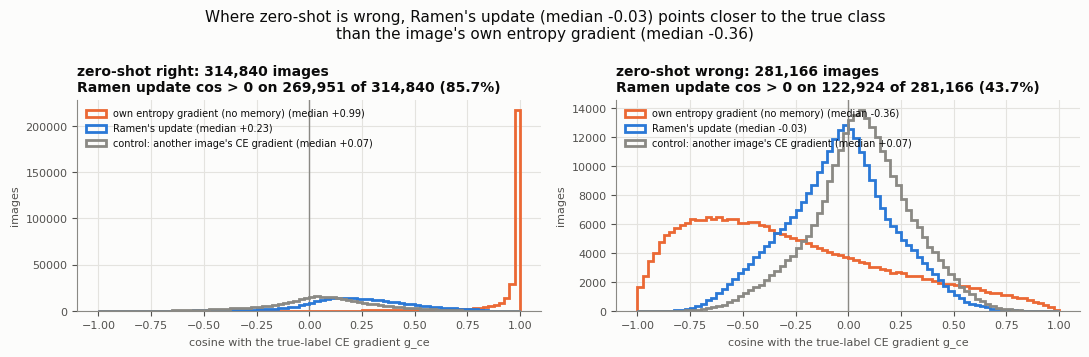

In [4]:
plot_cosine_distributions(df);
display(direction_summary(df, df['zs_ok'].map({True: 'zero-shot right', False: 'zero-shot wrong'})).round(3))

### 4.2 By outcome: images Ramen fixes, breaks, or leaves

Dumbbell per outcome group: orange = median cosine of the image's own entropy gradient, blue = of Ramen's update,
grey diamond = control. The line between them is what the memory changes.

,images,own entropy gradient (no memory),Ramen's update,control: another image's CE gradient,Ramen's sign step,sign agreement (step),sign agreement (own entropy),update cos > 0
outcome,,,,,,,,
both right,304538,0.992,0.233,0.070,0.052,0.579,0.996,"264,427 of 304,538 (86.8%)"
fixed by Ramen,20428,0.147,0.123,0.067,0.040,0.563,0.572,"15,354 of 20,428 (75.2%)"
broken by Ramen,10302,0.712,0.013,0.065,0.003,0.504,0.853,"5,524 of 10,302 (53.6%)"
both wrong,260738,-0.390,-0.048,0.067,-0.005,0.492,0.315,"107,570 of 260,738 (41.3%)"


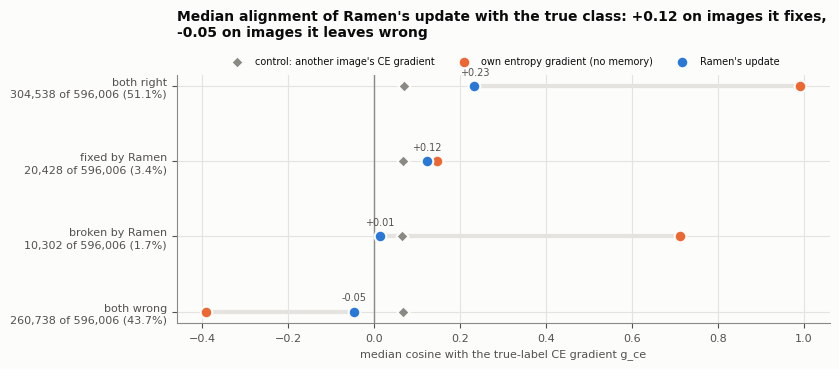

In [5]:
plot_outcome_dumbbell(df);
display(direction_summary(df, 'outcome').round(3))

### 4.3 By domain

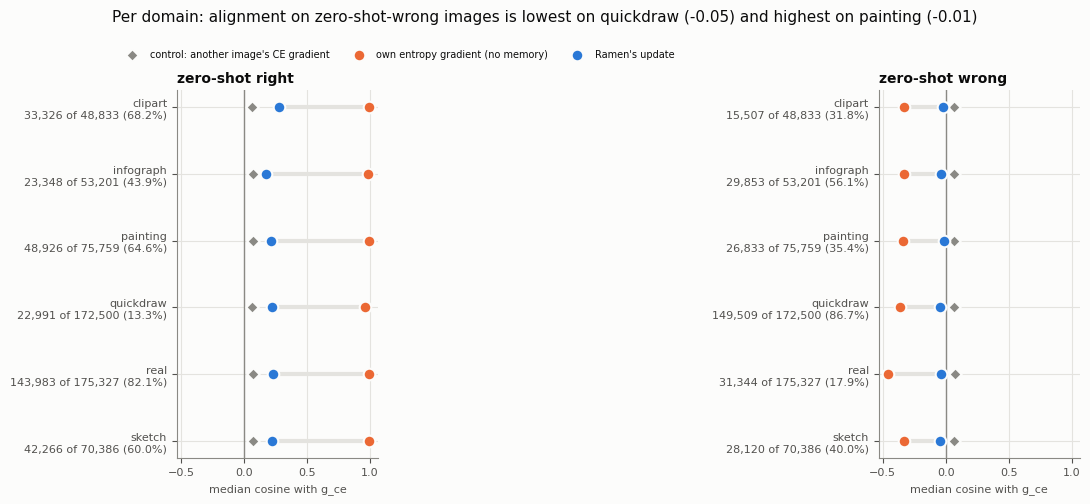

In [6]:
plot_domain_dumbbell(df);

### 4.4 Over the stream

Rolling mean over stream position. The dashed line marks where fewer than half of the images still get their own
entry stored (Ramen's fp16 arrival counter saturates after 65,520 inserts and full queues stop updating).

own entry stored for 168,423 of 596,006 images; mostly frozen from position 163,840


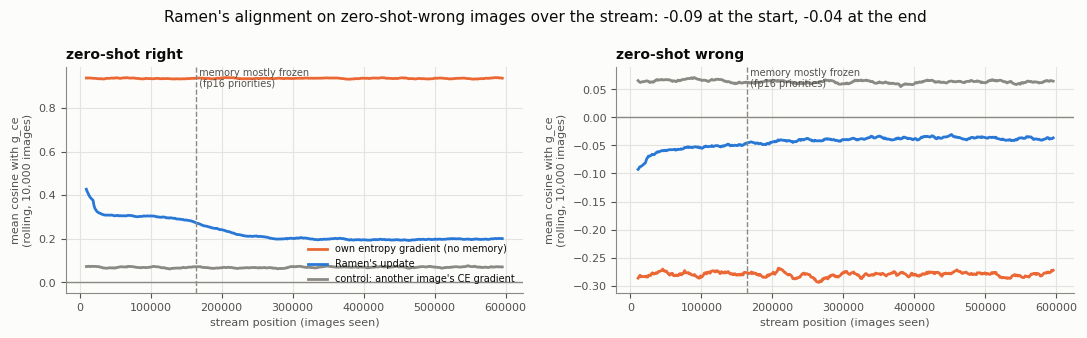

In [7]:
freeze = memory_freeze_position(df)
print(f'own entry stored for {int((df.part_self != 0).sum()):,} of {len(df):,} images; '
      f'mostly frozen from position {freeze:,}' if freeze else 'memory never freezes')
plot_stream(df, window=10_000, freeze_at=freeze);

## 5. Mechanism

### 5.1 Which memory entries make the update aligned?

The alignment $\cos(\hat g_i, g^{CE}_i)$ split exactly into the four parts of the update (section "Method"):
the image's own entry, other entries of the true-class queue, other entries of the wrong zero-shot-class queue, and
all other queues. Bars are means over images; the black tick is the total.

,images,part_self,part_true,part_zs,part_other,cos_update
outcome,,,,,,
both right,304538,0.042,0.016,0.000,0.182,0.240
fixed by Ramen,20428,0.002,0.013,-0.002,0.116,0.130
broken by Ramen,10302,0.003,0.009,0.000,0.009,0.021
both wrong,260738,-0.008,0.003,-0.006,-0.046,-0.057


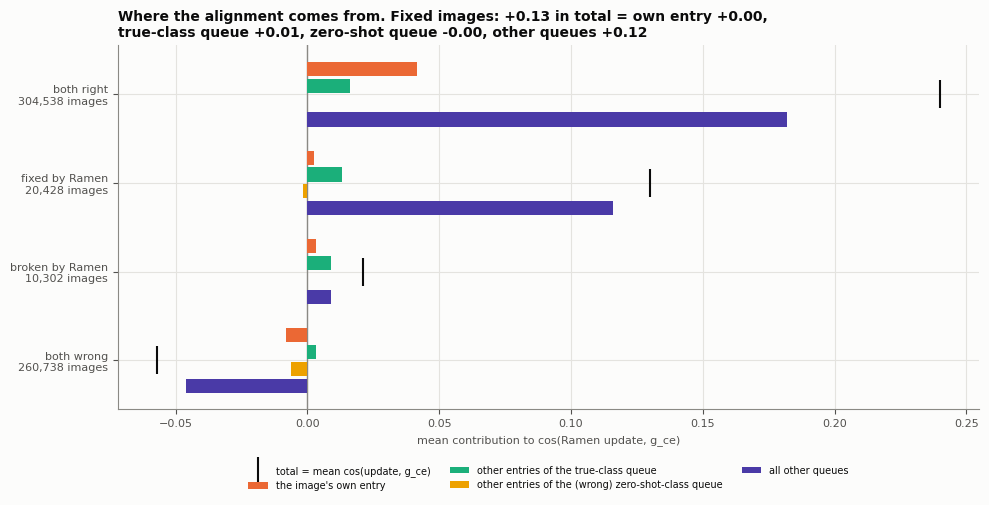

In [8]:
display(decomposition(df).round(3))
plot_decomposition(df);

### 5.2 Does alignment predict whether Ramen fixes or breaks an image?

Images are split into deciles of $\cos(\operatorname{sign} \hat g_i, g^{CE}_i)$ (the step Ramen takes) within each
zero-shot group. Left: share of zero-shot errors Ramen fixes; middle: share of zero-shot hits it breaks; right:
median change of $\log p(y_i)$ caused by the step. Counts in the end labels.

,group,bin,x,images,events,rate,dlogp_median
0,zero-shot right,"(-0.208, 0.00511]",-0.006,31484,5490,0.174,-0.007
1,zero-shot right,"(0.00511, 0.0188]",0.013,31484,1716,0.055,0.029
2,zero-shot right,"(0.0188, 0.0296]",0.024,31484,996,0.032,0.049
3,zero-shot right,"(0.0296, 0.0399]",0.035,31484,704,0.022,0.047
4,zero-shot right,"(0.0399, 0.0504]",0.045,31484,529,0.017,0.038
5,zero-shot right,"(0.0504, 0.062]",0.056,31484,397,0.013,0.030
6,zero-shot right,"(0.062, 0.0768]",0.069,31484,261,0.008,0.023
7,zero-shot right,"(0.0768, 0.102]",0.087,31484,147,0.005,0.024
8,zero-shot right,"(0.102, 0.16]",0.126,31484,52,0.002,0.056
9,zero-shot right,"(0.16, 0.404]",0.211,31484,10,0.000,0.107


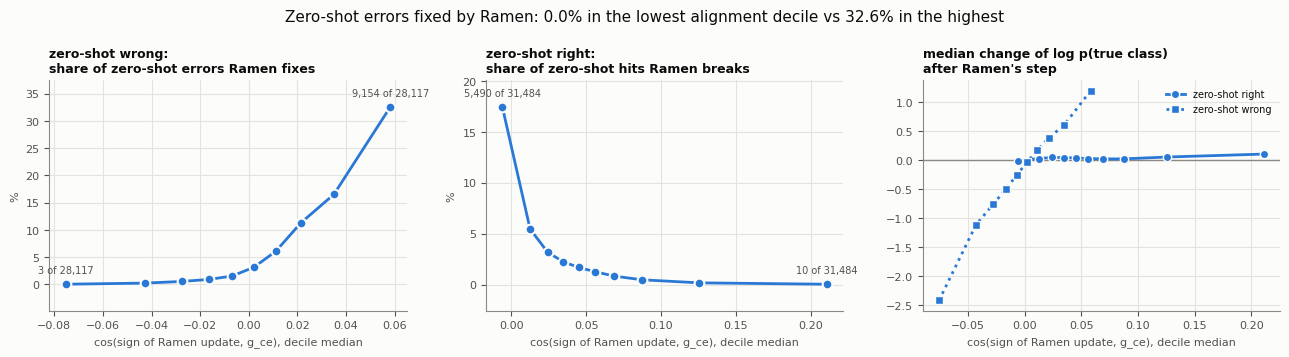

In [9]:
plot_outcome_vs_alignment(df);
display(binned_outcome_rates(df).round(3))

## 6. Pre-registered hypotheses

In [10]:
display(hypotheses(df))

,test,numbers,holds
hypothesis,,,
H1,"median cos(update, g_ce) > median control cos(...",+0.106 vs +0.068,True
H2,"zero-shot wrong: median cos(update, g_ce) > me...","-0.035 vs -0.363 (281,166 images)",True
H3a,zero-shot wrong: fix rate rises with cos(sign ...,fix rate 0.0% (lowest bin) -> 32.6% (highest);...,True
H3b,"images Ramen breaks: median cos(sign step, g_c...","+0.003 (10,302 images; zero-shot right overall...",False


## 7. Interpretation (DomainNet, seed 0, 596,006 images)

**In one line.** Ramen's update is not a "true-class" direction. Where zero-shot is wrong, the memory turns the
image's own entropy gradient, which points *away* from the true class (median cosine −0.36), into a nearly
neutral direction (−0.035). That is no better than chance and below the shuffled control (+0.067). The images Ramen
fixes are the minority whose averaged update happens to tilt toward the true class (median +0.12). That tilt comes
almost entirely from the other 340-odd queues, not from the true class's own queue.

**What the numbers show.**
- **Zero-shot right (314,840 images, 52.8%).** The own entropy gradient is almost the CE gradient (median cosine
  0.99): minimising entropy *is* minimising cross-entropy toward the predicted label, and here that label is right.
  Ramen's averaged update keeps only part of that direction (median 0.23; positive on 269,951 of 314,840 = 85.7%).
  It still raises p(true class) on most images, so the dilution costs little: 10,302 breaks (3.3% of these images).
- **Zero-shot wrong (281,166 images, 47.2%).** Own entropy gradient: median −0.36, i.e. it would push further toward
  the wrong class. Ramen's update: median −0.035, positive on 122,924 of 281,166 (43.7%). Its sign step agrees with
  the oracle on 49.6% of the oracle's gradient mass, which is chance (50%). **The memory removes the harmful
  self-direction but does not replace it with the true-class direction** (H2 holds only in this weak sense).
- **Control.** Any image's update has cosine +0.07 with *another* image's CE gradient, a direction all images
  share. Measured against this, Ramen is above the control on zero-shot-right images (+0.23), on fixed images (+0.12)
  and over all images (+0.106 vs +0.068, H1 holds). On zero-shot-wrong images it is *below* the control (−0.035).
- **Fixed (20,428) vs broken (10,302).** Fixed images get +0.12 (75.2% positive). Broken images had a good own
  direction (+0.71) and Ramen replaced it with a neutral one (+0.013). H3b expected broken images to be *negative*.
  They are at about zero (+0.003 for the sign step), so H3b fails: Ramen breaks images by losing the right
  direction, not by reversing it.
- **Alignment decides the outcome (H3a).** Among zero-shot errors, the fix rate rises from 0.0% (3 of 28,117) in the
  lowest decile of cos(sign step, g_ce) to 32.6% (9,154 of 28,117) in the highest. Among zero-shot hits, the break
  rate falls from 17.4% (5,490 of 31,484) to 0.0% (10 of 31,484). This is partly expected: to first order the
  change of the true-label loss is proportional to this cosine. It confirms that one step with η = 0.01 is close to
  linear, so **any change that raises this cosine should convert directly into fixes.**
- **Where the alignment comes from (section 5.1).** Fixed images: +0.130 in total, of which other queues +0.116,
  the true-class queue +0.013, own entry +0.002 and the zero-shot queue −0.002. Correctly filed same-class
  neighbours contribute almost nothing. This matches the label-value oracle (2026-11-01: the image's own class gets
  ~2.5% of the update weight). The equal average over ~345 queues swamps the one queue that holds the right class.
- **Domains** behave alike. Zero-shot-wrong medians are −0.05 (quickdraw) to −0.01 (painting); quickdraw also has
  86.7% of its images wrong at zero-shot.
- **Over the stream.** On zero-shot-right images the alignment falls from ~0.43 to ~0.20 as more queues fill (each
  queue's share is 1/|C|). It drops again once the fp16 priority counter saturates (from position ~164k). Only
  168,423 of 596,006 images (28.3%) get their own entry stored. On zero-shot-wrong images it creeps from −0.09
  to −0.04.

**What this does not show.**
- One seed and one dataset. ImageNet-C (notebook 02) and EuroSAT (03) are needed before generalising. EuroSAT is
  where label values gave +26.70, so it is the most likely place to see a different picture.
- Cosines in a 39,936-dimensional space are small in absolute terms (random directions: about ±0.005), so +0.05
  is far from chance. The shuffled control (+0.07), not zero, is the fair baseline for "image-specific".
- The first-order link between cosine and outcome is a measurement, not a cause. It says what a better
  direction would buy; it does not say how to obtain one without labels.
- Zero-shot = the prediction Ramen filed each image under. It differs from the cached NoAdapt run on 1,050 of
  596,006 images (0.18%, fp16 near-ties).

**Next step.** Run notebooks 02 (ImageNet-C) and 03 (EuroSAT). If the pattern holds (neutralising, not
redirecting), a label-free change should raise cos(sign ĝ, g_ce) on zero-shot-wrong images *without* lowering it on
zero-shot-right ones. Examples: give the true-class queue more weight than an equal 1/|C| share, or use a
retrieval that is not an average over all queues. The global top-k oracle (+2.86 on DomainNet) points the same way.
Section 5.2 can then be reused to check, before any accuracy run, whether a candidate moves the cosine.


## 8. Glossary

| Term | Meaning |
|---|---|
| Ramen | Test-time adaptation for CLIP: per-class memory of past images' entropy gradients; each image takes one SignSGD step along a weighted average of retrieved gradients, predicts, and resets |
| zero-shot | CLIP's prediction without adaptation ($\hat y_i$); Ramen files each image in this class's queue |
| $g^{CE}$ (oracle gradient) | gradient of the cross-entropy toward the **true** label; uses ground truth, so it is a measuring stick, not something a method can use |
| own entropy gradient $g_i$ | gradient of the image's own prediction entropy; minimising it sharpens the current prediction, right or wrong |
| Ramen's update $\hat g_i$ | the retrieved, weighted average of stored entropy gradients that Ramen steps along |
| sign step | Ramen moves by $-\eta\,\mathrm{sign}(\hat g_i)$, so only the sign of each coordinate matters for the step |
| cosine similarity | $\langle a, b\rangle / (\lVert a\rVert \lVert b\rVert)$, from −1 (opposite) through 0 (unrelated) to +1 (same direction) |
| sign agreement | share of $\lvert g^{CE}\rvert$ mass on coordinates where the sign step moves the same way as the oracle; 0.5 = chance |
| shuffled control | cosine of an image's update with *another* image's $g^{CE}$; alignment shared by all images, not specific to the true class |
| own entry | the image's own memory entry, written before retrieval and retrieved at distance ≈ 0 |
| fixed / broken | zero-shot wrong → Ramen right / zero-shot right → Ramen wrong |
| fp16 freeze | Ramen's arrival counter is stored in fp16 and saturates after 65,520 images; full queues then stop accepting new entries |
| pooled accuracy | correct images / all images (here), as opposed to the domain-averaged accuracy used for headline numbers |
